# Praktikum 3

In [1]:
# import library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

In [2]:
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none', edgecolors='black')
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

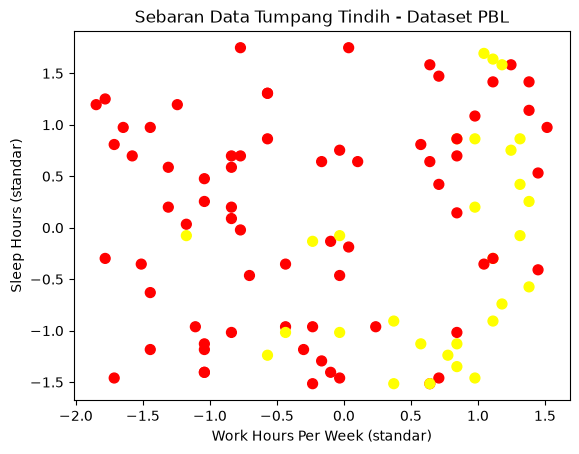

In [3]:
# Memuat data tumpang tindih dari Dataset PBL (Work_Hours_Per_Week vs Sleep_Hours)
raw_df = pd.read_csv('burnout_dataset1.csv')
df_ov = raw_df[['Work_Hours_Per_Week', 'Sleep_Hours', 'Burnout_Risk']].dropna().sample(n=100, random_state=0)

scaler = StandardScaler()
X = scaler.fit_transform(df_ov[['Work_Hours_Per_Week', 'Sleep_Hours']].to_numpy())
y = (df_ov['Burnout_Risk'] == 'High').astype(int).to_numpy()

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.xlabel('Work Hours Per Week (standar)')
plt.ylabel('Sleep Hours (standar)')
plt.title('Sebaran Data Tumpang Tindih - Dataset PBL')
plt.show()

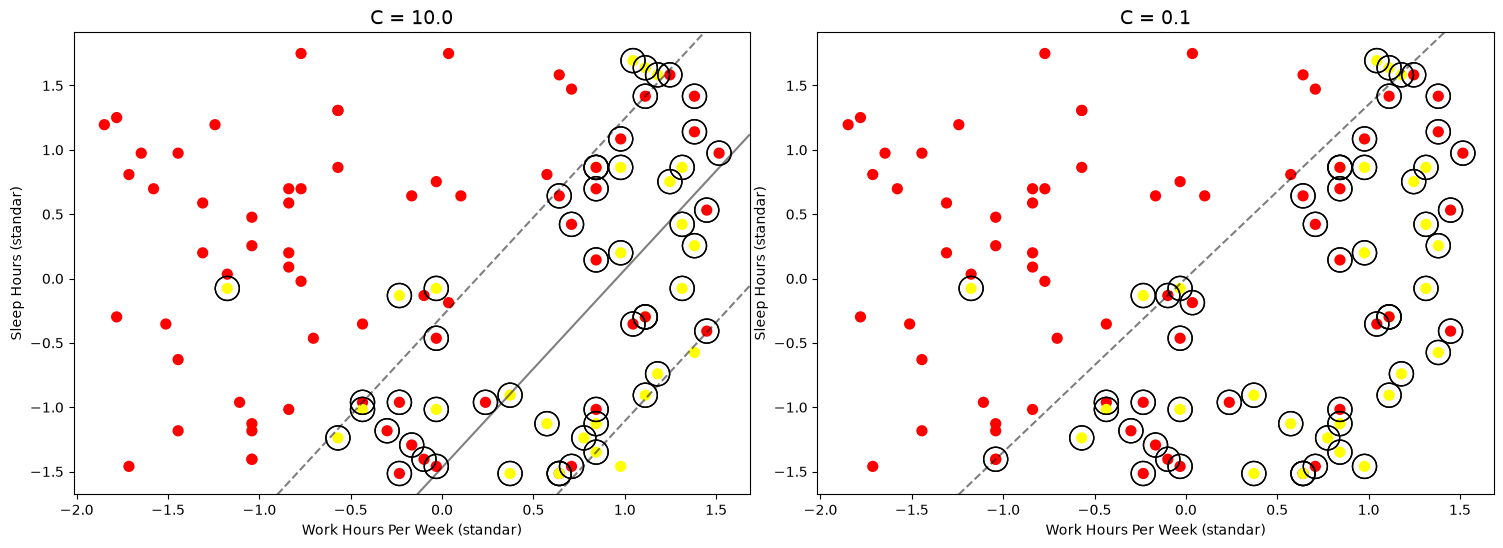

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

for axi, C in zip(ax, [10.0, 0.1]):
    model = SVC(kernel='linear', C=C).fit(X, y)
    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    plot_svc_decision_function(model, axi)
    axi.scatter(model.support_vectors_[:, 0],
                model.support_vectors_[:, 1],
                s=300, lw=1, facecolors='none', edgecolors='black')
    axi.set_title('C = {0:.1f}'.format(C), size=14)
    axi.set_xlabel('Work Hours Per Week (standar)')
    axi.set_ylabel('Sleep Hours (standar)')
plt.show()